# Zenodo metadata EDA -- for the multimodal fusion pipeline

Explores `Imagewise_Data.csv` and `Patientwise_Data.csv` -- the metadata
branch of the fusion architecture (Age, Gender, Chewing, Alcohol, Smoking,
Clinical Diagnosis) -- before it goes anywhere near a model. Goal: understand
distributions, missingness, and correlations with `Category`, and flag
anything that would make the metadata branch behave badly once fused with
the image branch.

## The most important finding, up front

**`Clinical Diagnosis` is not an independent feature -- it's a near-restatement
of `Category`.** "Leukoplakia" -> OPMD, "Oral Cancer" -> OCA, "Normal Mucosa"
-> Healthy, and so on, almost one-to-one (Section 3 confirms this with an
actual crosstab). If `Clinical Diagnosis` goes into the metadata branch of a
model that predicts `Category`, the model doesn't need to fuse anything -- it
just reads the diagnosis off a lookup table and the "multimodal" fusion
becomes fake. **`Clinical Diagnosis` is excluded from the metadata feature
set used for fusion/classification in this notebook and the ones after it.**
It's kept only as a descriptive/EDA column and, if you want it later, as an
*auxiliary* target for a different, diagnosis-level model -- never as an
input feature for a Category classifier.

The real metadata modality is: **Age, Gender, Smoking, Chewing_Betel_Quid,
Alcohol** -- true patient-level risk factors, independent of the label.


In [1]:
# ============================================================
# 1. CONFIG -- enter your paths when prompted
# ============================================================
from pathlib import Path


def ask_path(prompt, must_exist=True, is_file=False):
    while True:
        raw = input(prompt).strip().strip('"').strip("'")
        if not raw:
            print("  -> can't be empty, try again.")
            continue
        p = Path(raw).expanduser()
        if must_exist and not p.exists():
            print(f"  -> {p} doesn't exist, try again.")
            continue
        if must_exist and is_file and not p.is_file():
            print(f"  -> {p} exists but isn't a file, try again.")
            continue
        if must_exist and not is_file and not p.is_dir():
            print(f"  -> {p} exists but isn't a folder, try again.")
            continue
        return p


IMAGEWISE_CSV = ask_path("Path to Imagewise_Data.csv: ", must_exist=True, is_file=True)
PATIENTWISE_CSV = ask_path("Path to Patientwise_Data.csv: ", must_exist=True, is_file=True)
# This is the split_assignment.csv produced by the patient-level train/val/test
# split notebook (zenodo-patient-level-train-val-test-split.ipynb). Section 9
# below reuses THAT split -- it does not create a new one -- so the metadata
# encoding and the image folders always agree on which patient is in which set.
SPLIT_ASSIGNMENT_CSV = ask_path(
    "Path to split_assignment.csv (from the train/val/test split notebook): ",
    must_exist=True, is_file=True,
)
OUTPUT_DIR = ask_path("Output folder for EDA figures/tables (created if missing): ", must_exist=False)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print()
print("Imagewise CSV        :", IMAGEWISE_CSV)
print("Patientwise CSV      :", PATIENTWISE_CSV)
print("Split assignment CSV :", SPLIT_ASSIGNMENT_CSV)
print("Output folder        :", OUTPUT_DIR)



Imagewise CSV        : /Users/annapoornaak/Desktop/College /Oral Cancer/Dataset/Zenodo/Dataset/Imagewise_Data.csv
Patientwise CSV      : /Users/annapoornaak/Desktop/College /Oral Cancer/Dataset/Zenodo/Dataset/Patientwise_Data.csv
Split assignment CSV : /Users/annapoornaak/Desktop/College /Oral Cancer/Code Files/After fine tuning mobileunet/train test vali zenodo/split_assignment.csv
Output folder        : /Users/annapoornaak/Desktop/College /Oral Cancer/Code Files/After fine tuning mobileunet/output for zenodo metadata eda


In [2]:
# ============================================================
# 2. LOAD + MERGE
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

img_df = pd.read_csv(IMAGEWISE_CSV)
img_df["Image Name"] = img_df["Image Name"].astype(str)

pat_df = pd.read_csv(PATIENTWISE_CSV)
pat_df.columns = [c.strip() for c in pat_df.columns]   # trims the stray trailing space in some column names

def patient_id_from_image_name(name: str) -> str:
    parts = name.split("-")
    return f"{parts[0]}-{parts[1]}"

img_df["patient_id"] = img_df["Image Name"].apply(patient_id_from_image_name)

id_col = "Patient ID" if "Patient ID" in pat_df.columns else pat_df.columns[0]
merged = img_df.merge(pat_df, left_on="patient_id", right_on=id_col, how="left")

print(f"Image-level rows : {len(img_df)}")
print(f"Patient-level rows: {len(pat_df)}")
print(f"Merged rows       : {len(merged)}  (should equal image-level rows)")
print()
print("Columns available:", list(merged.columns))
merged.to_csv(OUTPUT_DIR / "merged_image_patient_metadata.csv", index=False)


Image-level rows : 3000
Patient-level rows: 714
Merged rows       : 3000  (should equal image-level rows)

Columns available: ['Image Name', 'Category', 'Clinical Diagnosis', 'Lesion Annotation Count', 'patient_id', 'Patient ID', 'Age', 'Gender', 'Smoking', 'Chewing_Betel_Quid', 'Alcohol', 'Image Count']


In [3]:
# ============================================================
# 3. THE HEADLINE FINDING -- Clinical Diagnosis vs. Category
# ============================================================
diag_vs_cat = pd.crosstab(merged["Clinical Diagnosis"], merged["Category"])
print(diag_vs_cat)
print()

# For each diagnosis, what fraction of its images fall in its single most common category?
purity = (diag_vs_cat.max(axis=1) / diag_vs_cat.sum(axis=1)).sort_values()
print("Diagnosis -> Category 'purity' (1.0 = diagnosis perfectly determines category):")
print(purity.to_string())
print()
mean_purity = purity.mean()
print(f"Mean purity across all diagnoses: {mean_purity:.3f}")
print("A value near 1.0 confirms Clinical Diagnosis is (almost) a deterministic function of")
print("Category -- i.e. it leaks the label. This is why it's excluded from the metadata")
print("feature set used for fusion/classification everywhere after this notebook.")
diag_vs_cat.to_csv(OUTPUT_DIR / "diagnosis_vs_category_crosstab.csv")


Category                  Benign  Healthy  OCA  OPMD
Clinical Diagnosis                                  
Alevolar Keratosis             1        0    0     0
Allergic Reaction              1        0    0     0
Allergy                       20        0    0     0
Alveolar Keratosis             4        0    0     0
Alveolar Kertitis              1        0    0     0
...                          ...      ...  ...   ...
Verucouss Ca                   0        0    1     0
Vesiculo Bullous Disease       3        0    0     0
Viral Infection/ RAU           2        0    0     0
Viral Wart                     3        0    0     0
White Coated Tongue            1        0    0     0

[155 rows x 4 columns]

Diagnosis -> Category 'purity' (1.0 = diagnosis perfectly determines category):
Clinical Diagnosis
Coated Tongue                                 0.966667
Leukoplakia                                   0.985714
OLP                                           0.994413
Normal Mucosa         

In [4]:
# ============================================================
# 4. MISSINGNESS
# ============================================================
meta_cols = ["Age", "Gender", "Smoking", "Chewing_Betel_Quid", "Alcohol"]
meta_cols = [c for c in meta_cols if c in merged.columns]
if "Chewing_Betel_Quid" not in merged.columns:
    # column name in the CSV has a trailing space sometimes -- already stripped above, but
    # double check for any near-miss so this notebook doesn't silently drop the column.
    close = [c for c in merged.columns if "chew" in c.lower()]
    print("Note: 'Chewing_Betel_Quid' not found as-is; closest match(es):", close)

print("Missing value counts (image-level, after merge):")
print(merged[meta_cols + ["Category"]].isna().sum())
print()
print("Missing value counts (patient-level, before merge -- catches patients absent from Patientwise_Data.csv):")
print(f"Patients in Imagewise but missing from Patientwise: {merged['Age'].isna().sum()} images affected")


Missing value counts (image-level, after merge):
Age                   0
Gender                0
Smoking               0
Chewing_Betel_Quid    0
Alcohol               0
Category              0
dtype: int64

Missing value counts (patient-level, before merge -- catches patients absent from Patientwise_Data.csv):
Patients in Imagewise but missing from Patientwise: 0 images affected


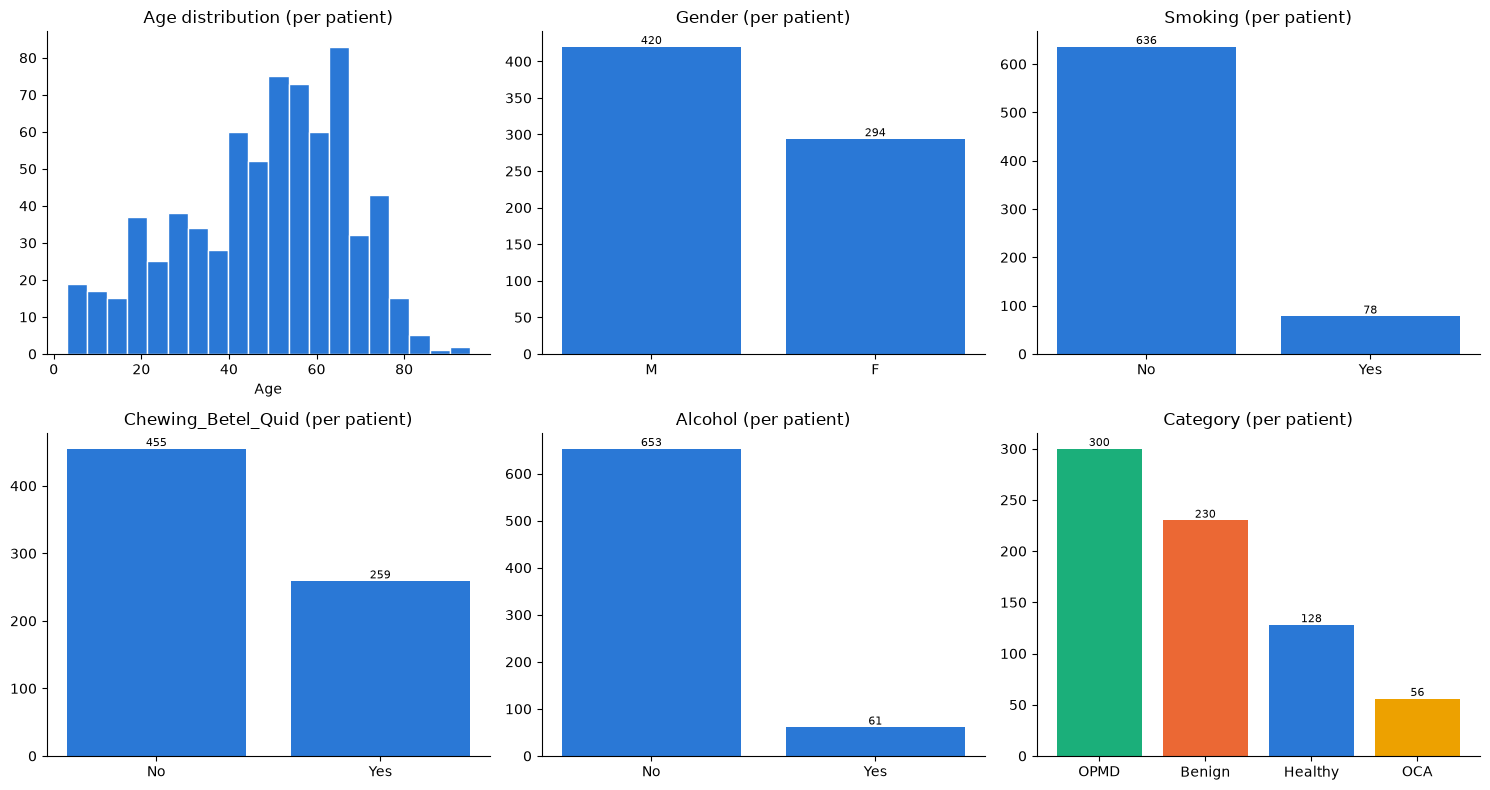

              Age
count  714.000000
mean    47.805322
std     18.982236
min      3.000000
25%     35.000000
50%     51.000000
75%     63.000000
max     95.000000


In [5]:
# ============================================================
# 5. UNIVARIATE DISTRIBUTIONS
#    Categorical color assigned by identity (Category), fixed order.
# ============================================================
CATEGORY_ORDER = [c for c in ["Healthy", "Benign", "OPMD", "OCA"] if c in merged["Category"].unique()]
CATEGORY_COLORS = {"Healthy": "#2a78d6", "Benign": "#eb6834", "OPMD": "#1baf7a", "OCA": "#eda100"}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Age -- patient-level (avoid double-counting patients with many images)
patient_level = merged.drop_duplicates("patient_id")
axes[0, 0].hist(patient_level["Age"].dropna(), bins=20, color="#2a78d6", edgecolor="white")
axes[0, 0].set_title("Age distribution (per patient)")
axes[0, 0].set_xlabel("Age"); axes[0, 0].spines[["top", "right"]].set_visible(False)

for ax, col in zip(axes.flat[1:], ["Gender", "Smoking", "Chewing_Betel_Quid", "Alcohol", "Category"]):
    if col not in patient_level.columns:
        ax.axis("off"); continue
    vc = patient_level[col].value_counts()
    colors = [CATEGORY_COLORS.get(v, "#7a7a7a") for v in vc.index] if col == "Category" else "#2a78d6"
    bars = ax.bar(vc.index.astype(str), vc.values, color=colors)
    ax.bar_label(bars, fontsize=8)
    ax.set_title(f"{col} (per patient)")
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "univariate_distributions.png", dpi=180, bbox_inches="tight")
plt.show()

print(patient_level[["Age"]].describe())


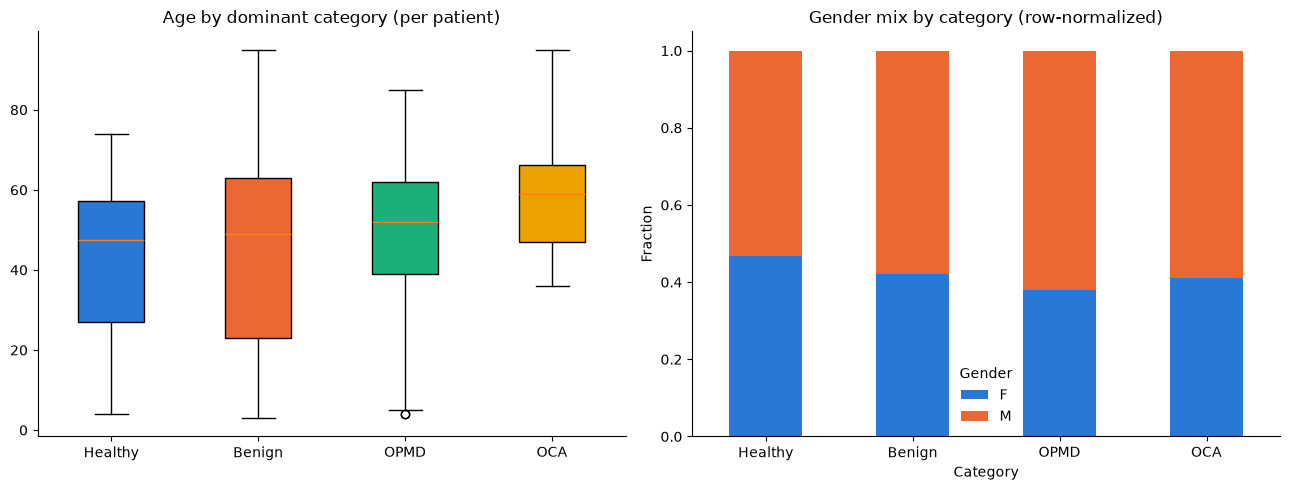

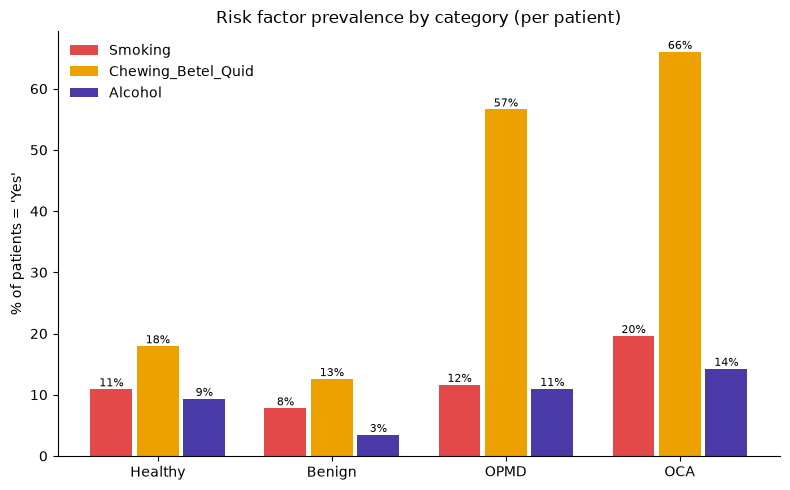

In [6]:
# ============================================================
# 6. BIVARIATE -- metadata vs. Category (the actual fusion target)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Age by category (patient-level, boxplot)
data_by_cat = [patient_level.loc[patient_level["Category"] == c, "Age"].dropna() for c in CATEGORY_ORDER]
bp = axes[0].boxplot(data_by_cat, tick_labels=CATEGORY_ORDER, patch_artist=True)
for patch, cat in zip(bp["boxes"], CATEGORY_ORDER):
    patch.set_facecolor(CATEGORY_COLORS[cat])
axes[0].set_title("Age by dominant category (per patient)")
axes[0].spines[["top", "right"]].set_visible(False)

# Gender x Category, row-normalized
gender_cat = pd.crosstab(patient_level["Category"], patient_level["Gender"], normalize="index").reindex(CATEGORY_ORDER)
gender_cat.plot(kind="bar", stacked=True, ax=axes[1], color=["#2a78d6", "#eb6834", "#1baf7a"])
axes[1].set_title("Gender mix by category (row-normalized)")
axes[1].set_ylabel("Fraction"); axes[1].legend(title="Gender", frameon=False)
axes[1].spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=0)

plt.tight_layout()
fig.savefig(OUTPUT_DIR / "age_gender_by_category.png", dpi=180, bbox_inches="tight")
plt.show()

# Risk factors (Smoking/Chewing/Alcohol) x Category -- % "Yes" per category
fig, ax = plt.subplots(figsize=(8, 5))
risk_cols = [c for c in ["Smoking", "Chewing_Betel_Quid", "Alcohol"] if c in patient_level.columns]
x = np.arange(len(CATEGORY_ORDER))
width = 0.8 / len(risk_cols)
risk_colors = {"Smoking": "#e34948", "Chewing_Betel_Quid": "#eda100", "Alcohol": "#4a3aa7"}
for i, col in enumerate(risk_cols):
    pct_yes = [
        (patient_level.loc[patient_level["Category"] == c, col] == "Yes").mean() * 100
        for c in CATEGORY_ORDER
    ]
    offsets = x - 0.4 + width * (i + 0.5)
    bars = ax.bar(offsets, pct_yes, width=width * 0.9, label=col, color=risk_colors.get(col, "#999"))
    ax.bar_label(bars, fmt="%.0f%%", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(CATEGORY_ORDER)
ax.set_ylabel("% of patients = 'Yes'")
ax.set_title("Risk factor prevalence by category (per patient)")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "risk_factors_by_category.png", dpi=180, bbox_inches="tight")
plt.show()


In [7]:
# ============================================================
# 7. STATISTICAL CHECKS -- is each metadata field actually associated
#    with Category, or is it noise? (Informs whether it's worth including.)
# ============================================================
print("Chi-square test of independence: categorical field vs. Category (patient-level)")
for col in ["Gender", "Smoking", "Chewing_Betel_Quid", "Alcohol"]:
    if col not in patient_level.columns:
        continue
    ct = pd.crosstab(patient_level[col], patient_level["Category"])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    sig = "SIGNIFICANT (p < 0.05)" if p < 0.05 else "not significant"
    print(f"  {col:20s}: chi2={chi2:7.2f}  p={p:.4f}  -> {sig}")

print()
print("One-way ANOVA: Age vs. Category (patient-level)")
groups = [patient_level.loc[patient_level["Category"] == c, "Age"].dropna() for c in CATEGORY_ORDER]
f_stat, p_val = stats.f_oneway(*groups)
sig = "SIGNIFICANT (p < 0.05)" if p_val < 0.05 else "not significant"
print(f"  Age: F={f_stat:.2f}  p={p_val:.4f}  -> {sig}")
print()
print("A field with p >= 0.05 isn't necessarily useless for a model (these are simple")
print("marginal tests, not accounting for interactions), but a field that's both")
print("statistically unassociated AND has no plausible clinical link to oral lesions is")
print("a reasonable one to drop from a small feature set rather than keep 'just in case'.")


Chi-square test of independence: categorical field vs. Category (patient-level)
  Gender              : chi2=   3.06  p=0.3824  -> not significant
  Smoking             : chi2=   6.81  p=0.0781  -> not significant
  Chewing_Betel_Quid  : chi2= 149.76  p=0.0000  -> SIGNIFICANT (p < 0.05)
  Alcohol             : chi2=  12.35  p=0.0063  -> SIGNIFICANT (p < 0.05)

One-way ANOVA: Age vs. Category (patient-level)
  Age: F=11.77  p=0.0000  -> SIGNIFICANT (p < 0.05)

A field with p >= 0.05 isn't necessarily useless for a model (these are simple
marginal tests, not accounting for interactions), but a field that's both
statistically unassociated AND has no plausible clinical link to oral lesions is
a reasonable one to drop from a small feature set rather than keep 'just in case'.


count    714.000000
mean       4.201681
std        2.639371
min        1.000000
25%        2.000000
50%        4.000000
75%        6.000000
max       18.000000
dtype: float64

Top 10 patients by image count (out of 714 total):
patient_id
N-270    18
N-277    15
R-219    14
N-272    13
N-355    13
N-265    12
R-259    11
R-261    11
R-270    11
R-243    11
dtype: int64

Top 10% of patients (by image count) contribute 22.4% of all images.


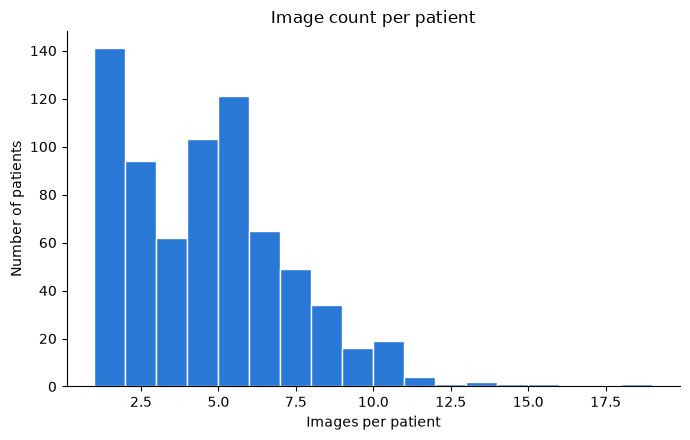

In [8]:
# ============================================================
# 8. IMAGE-COUNT IMBALANCE -- why patient-level aggregation matters here
#    A handful of patients contribute far more images than others, which can
#    make an IMAGE-level metadata model implicitly overweight those patients'
#    demographics without anyone intending it.
# ============================================================
img_per_patient = merged.groupby("patient_id").size()
print(img_per_patient.describe())
print()
print(f"Top 10 patients by image count (out of {merged['patient_id'].nunique()} total):")
print(img_per_patient.sort_values(ascending=False).head(10))
print()
top_decile_share = img_per_patient.sort_values(ascending=False).head(
    max(1, len(img_per_patient) // 10)).sum() / img_per_patient.sum()
print(f"Top 10% of patients (by image count) contribute {top_decile_share:.1%} of all images.")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(img_per_patient, bins=range(1, img_per_patient.max() + 2), color="#2a78d6", edgecolor="white")
ax.set_xlabel("Images per patient"); ax.set_ylabel("Number of patients")
ax.set_title("Image count per patient")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "images_per_patient.png", dpi=180, bbox_inches="tight")
plt.show()


## 9. Patient-level train/val/test split for the metadata branch

**We do not split again here.** The train/val/test split notebook already
did the patient-level split (no patient's images span two sets) and wrote
`split_assignment.csv`. Section 9 below just **joins that same split onto
the metadata**, so the metadata encoding and the image folders are always
talking about the exact same patients in the exact same sets -- which is
required for fusion (image feature vector and metadata vector for a given
sample must come from the same split).

It then:
1. Confirms the join is patient-clean (no patient appears in more than one split).
2. Fits the `Age` standardizer and the one-hot encoders **on the train split
   only**, and applies them, unchanged, to val and test.
3. Saves one encoded CSV per split (`metadata_encoded_train.csv`,
   `..._val.csv`, `..._test.csv`) plus a combined file with a `split` column
   -- ready to be loaded next to the image feature notebooks' saved
   embeddings in the fusion notebook.


In [9]:
# ============================================================
# 9a. JOIN THE EXISTING PATIENT-LEVEL SPLIT ONTO THE METADATA
#     (reuses split_assignment.csv from the split notebook -- does NOT
#     create a new split)
# ============================================================
split_df = pd.read_csv(SPLIT_ASSIGNMENT_CSV)
split_df["image_name"] = split_df["image_name"].astype(str)

# split_assignment.csv's `image_name` matches Imagewise_Data.csv's `Image Name`
# (both are the bare filename stem written by the split notebook).
meta_split = merged.merge(
    split_df[["image_name", "patient_id", "split"]],
    left_on=["Image Name", "patient_id"],
    right_on=["image_name", "patient_id"],
    how="inner",
)
meta_split = meta_split.drop(columns=["image_name"])

print(f"Metadata rows matched to a split: {len(meta_split)} / {len(merged)}")
unmatched = set(merged["Image Name"]) - set(split_df["image_name"])
if unmatched:
    print(f"WARNING -- {len(unmatched)} metadata rows had no matching entry in "
          f"split_assignment.csv (image renamed/missing from the split run?): "
          f"{list(unmatched)[:10]}")
else:
    print("Every metadata row matched a split assignment.")

# Hard patient-level leakage check: no patient_id should appear in more than one split.
patient_split_counts = meta_split.groupby("patient_id")["split"].nunique()
leaking_patients = patient_split_counts[patient_split_counts > 1]
assert len(leaking_patients) == 0, (
    f"Patient-level leakage across splits! These patients appear in more than "
    f"one split: {list(leaking_patients.index)}"
)
print("Leakage check passed -- every patient's rows fall in exactly one split.")
print()
print(meta_split.groupby("split")["patient_id"].nunique().rename("patients"))
print(meta_split["split"].value_counts().rename("images"))


Metadata rows matched to a split: 3000 / 3000
Every metadata row matched a split assignment.
Leakage check passed -- every patient's rows fall in exactly one split.

split
test     119
train    476
val      119
Name: patients, dtype: int64
split
train    1933
test      550
val       517
Name: images, dtype: int64


In [10]:
# ============================================================
# 9b. ENCODE -- fit on TRAIN split only, apply unchanged to val/test
# ============================================================
FEATURE_COLS = ["Age", "Gender", "Smoking", "Chewing_Betel_Quid", "Alcohol"]
FEATURE_COLS = [c for c in FEATURE_COLS if c in meta_split.columns]
print("Metadata feature columns used:", FEATURE_COLS)

train_rows = meta_split[meta_split["split"] == "train"]

# --- Age: z-score standardize, fit mean/std on train only ---
age_mean = train_rows["Age"].mean()
age_std = train_rows["Age"].std()
print(f"Age standardizer fit on train only -- mean={age_mean:.3f}, std={age_std:.3f}")

encoded = meta_split.copy()
encoded["Age_zscore"] = (encoded["Age"] - age_mean) / age_std

# --- Categorical fields: one-hot, categories fixed from train only so val/test
#     can never introduce a category the model never saw trained on ---
cat_cols = [c for c in FEATURE_COLS if c != "Age"]
onehot_frames = [encoded[["Image Name", "patient_id", "split", "Category"]], encoded[["Age_zscore"]]]
for col in cat_cols:
    train_categories = sorted(train_rows[col].dropna().unique())
    print(f"{col}: categories fixed from train = {train_categories}")
    dummies = pd.get_dummies(encoded[col], prefix=col)
    # keep only train-seen categories (drops/ignores anything unseen-in-train that
    # might appear in val/test, rather than silently adding a new column for it)
    keep_cols = [f"{col}_{v}" for v in train_categories if f"{col}_{v}" in dummies.columns]
    onehot_frames.append(dummies[keep_cols])

metadata_encoded = pd.concat(onehot_frames, axis=1)
print()
print(f"Final encoded metadata table: {metadata_encoded.shape[0]} rows x {metadata_encoded.shape[1]} columns")
print(metadata_encoded.head())

metadata_encoded.to_csv(OUTPUT_DIR / "metadata_encoded_all_splits.csv", index=False)
for s in ["train", "val", "test"]:
    subset = metadata_encoded[metadata_encoded["split"] == s]
    subset.to_csv(OUTPUT_DIR / f"metadata_encoded_{s}.csv", index=False)
    print(f"Saved metadata_encoded_{s}.csv -- {len(subset)} rows")


Metadata feature columns used: ['Age', 'Gender', 'Smoking', 'Chewing_Betel_Quid', 'Alcohol']
Age standardizer fit on train only -- mean=47.847, std=17.680
Gender: categories fixed from train = ['F', 'M']
Smoking: categories fixed from train = ['No', 'Yes']
Chewing_Betel_Quid: categories fixed from train = ['No', 'Yes']
Alcohol: categories fixed from train = ['No', 'Yes']

Final encoded metadata table: 3000 rows x 13 columns
  Image Name patient_id  split Category  Age_zscore  Gender_F  Gender_M  \
0    R-01-01       R-01  train     OPMD    0.857056     False      True   
1    R-01-02       R-01  train     OPMD    0.857056     False      True   
2    R-01-03       R-01  train   Benign    0.857056     False      True   
3    R-02-01       R-02  train   Benign   -1.744778      True     False   
4    R-02-02       R-02  train   Benign   -1.744778      True     False   

   Smoking_No  Smoking_Yes  Chewing_Betel_Quid_No  Chewing_Betel_Quid_Yes  \
0        True        False                  